# Snowballing nested sampling

This notebook demonstrates the `SnowballingNestedSampler`
(`ultranest.snowballingns`), a nested sampler that advances *batches* of
`P` threads (lineages) at once, and integrates the dead points itself.

It works in *snowball rotations*: each rotation advances the `P`
lowest-likelihood thread ends in batches, buries the dead points the
front has passed (the *burial gate*), integrates them with `1/K` strips,
and then *widens* by doubling `K` with fresh prior draws for the next
rotation. The number of live points therefore grows exponentially, and
each rotation re-integrates everything at the new width.

We use the same 7-dimensional two-component sine model as in the
higher-dimensional fitting notebook, and the same data set.


## Model and data


In [1]:
import numpy as np
from numpy import sin, pi

def sine_model1(t, B, A1, P1, t1):
    return A1 * sin((t / P1 + t1) * 2 * pi) + B

def sine_model2(t, B, A1, P1, t1, A2, P2, t2):
    return A1 * sin((t / P1 + t1) * 2 * pi) + A2 * sin((t / P2 + t2) * 2 * pi) + B

np.random.seed(42)

n_data = 50
t = np.random.uniform(0, 5, size=n_data)
yerr = 1.0
y = np.random.normal(sine_model2(t, B=1.0, A1=4.2, P1=3, t1=0, A2=1.2, P2=1.2, t2=1.2), yerr)

parameters2 = ['B', 'A1', 'P1', 't1', 'A2', 'P2', 't2']


## Visualise the data


<ErrorbarContainer object of 3 artists>

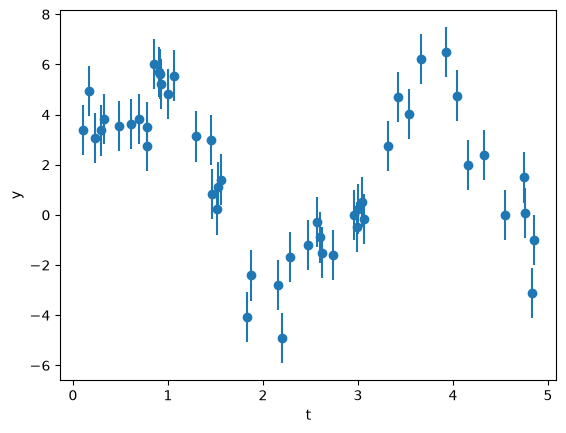

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure()
plt.xlabel('t')
plt.ylabel('y')
plt.errorbar(x=t, y=y, yerr=yerr, ls='none', marker='o')


## Setting up the sampler

The `SnowballingNestedSampler` takes a vectorized prior transform and a
vectorized likelihood function (arrays of points in, array of
likelihoods out), and a `log_dir` where the growing HDF5 point store,
the rotation records and the plots are written.

Its main settings:

* the number of live points starts at `num_live_points_base` (default 50)
  and doubles with each rotation (widening);
* `P` (default: half the live points, capped at 100) threads are advanced
  per batch advance;
* the direction proposal is a step sampler function, by default the
  quadratic slice direction;
* the region proposal pool (the points the directions are drawn from) is
  padded with the most recent dead points to at least `min_point_pool`
  (default 400), so small `K` still keeps proposal diversity;
* the `integrator='custom'` path integrates the dead points with `1/K`
  strips inside the state machine.


In [3]:
def prior_transform(cube):
    params = cube.copy()
    # let background level go from -10 to +10
    params[:, 0] = cube[:, 0] * 20 - 10
    # let amplitude go from 0.1 to 100
    params[:, 1] = 10**(cube[:, 1] * 3 - 1)
    # let period go from 0.3 to 30
    params[:, 2] = 10**(cube[:, 2] * 2)
    # let time go from 0 to 1
    params[:, 3] = cube[:, 3]
    params[:, 4] = 10**(cube[:, 4] * 3 - 1)
    params[:, 5] = 10**(cube[:, 5] * 2)
    params[:, 6] = cube[:, 6]
    return params

def log_likelihood(params):
    B, A1, P1, t1, A2, P2, t2 = params.transpose()
    # evaluate the model for all points at once:
    # y_model has shape (n_data, n_points)
    y_model = sine_model2(
        t[:, None], B=B[None, :], A1=A1[None, :], P1=P1[None, :],
        t1=t1[None, :], A2=A2[None, :], P2=P2[None, :], t2=t2[None, :])
    loglike = -0.5 * (((y_model - y[:, None]) / yerr)**2).sum(axis=0)
    # avoid unnecessary multiple solutions:
    #    force ordering by period from large to small
    swap = P1 < P2
    loglike[swap] = -1e300 * np.abs(P1[swap] - P2[swap])
    return loglike

from ultranest.snowballingns import SnowballingNestedSampler

sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, integrator='custom',
    log_dir='chains/snowball-quicklook')


## Quick-look result: a single rotation

`run(max_rotations=1)` performs a single snowball rotation: the `K=50`
threads are advanced in batches of `P=25` until the `frac_remain`
criterion fires, and the buried dead points are integrated with `1/K`
strips. The corner plot is written to `log_dir` after the rotation.


In [4]:
result = sampler.run(frac_remain=0.5, max_rotations=1, resume=False)
sampler.plot_corner()

from IPython.display import IFrame
IFrame('chains/snowball-quicklook/corner.pdf', width=620, height=480)


rotation 1: K=50, 1242 buried cells, lnZ = -58.8126 +- 0.6353


convergence criterion fulfilled: False


### Reading the output

The printed line `rotation 1: K=50, N buried cells, lnZ = ... +- ...`
reports:

* `K` – the number of live points (threads) used in this rotation;
* `N buried cells` – how many dead points passed the burial gate; each is
  one completed walk, integrated with a `1/K` strip;
* `lnZ +- ...` – the evidence integrated so far, plus the estimated error
  `sqrt(H/K)` (the information divided by the live points).

The final line `convergence criterion fulfilled: False` reports whether
the Gompertz looping criterion fired. With a single rotation it cannot:
this is *not* a converged result.

The corner plot shows the quick-look posterior: the buried dead points,
weighted by their `1/K` strips, plus the thread ends, weighted by the
remaining volume. After one rotation the remaining-volume term still
holds a large share of the probability mass, so the evidence is only
partial and the posterior is broad — it is a look at where the sampler
is, not a final answer.


## Full run

The full run lets the rotations widen `K` until the Gompertz looping
criterion says the next doubling is not worth it. The `max_ncalls` and
`max_time` budgets terminate the run at the next rotation boundary even
if the criterion has not fired — and `results['converged']` records
whether it did. The final corner plot is written as `corner.pdf`.


In [5]:
full_sampler = SnowballingNestedSampler(
    parameters2, log_likelihood, transform=prior_transform,
    vectorized=True, num_steps=1, integrator='custom',
    log_dir='chains/snowball-full')

result = full_sampler.run(
    frac_remain=0.5, max_ncalls=1000000, max_time=2*60*60, resume=False)


rotation 1: K=50, 1242 buried cells, lnZ = -58.8126 +- 0.6353


rotation 2: K=100, 2400 buried cells, lnZ = -57.2117 +- 0.4319


rotation 3: K=200, 4200 buried cells, lnZ = -54.4066 +- 0.2887


rotation 4: K=400, 13321 buried cells, lnZ = -50.6172 +- 0.2419


rotation 5: K=800, 22750 buried cells, lnZ = -45.2891 +- 0.1639


rotation 6: K=1600, 44400 buried cells, lnZ = -44.1820 +- 0.1151


rotation 7: K=3200, 89475 buried cells, lnZ = -43.9640 +- 0.0815


max_ncalls=1000000 reached before convergence (ncall=1409475); stopping.


convergence criterion fulfilled: False


In [6]:
full_sampler.plot_corner()

from IPython.display import IFrame
IFrame('chains/snowball-full/corner.pdf', width=620, height=480)
print('lnZ = %.3f +- %.3f' % (result['logz'], result['logzerr']))
print('converged:', result['converged'])


lnZ = -43.964 +- 0.082
converged: False


The corner plot now shows the posterior from the accumulated dead
points of all rotations, weighted by their strips, with the thread ends
contributing only a small remaining-volume weight. The `K` of the last
rotation is the accuracy knob: the error estimate scales as
`sqrt(H/K)`.